# Designed hierarchy initialisations, part 2: one section per run

Continuation of `hierarchy_design_runs.ipynb` (runs 1-46 there), started on 2026-10-13 because that notebook had grown too big. **Runs
keep their global numbers** (41, then 47, 48, ... so that "run x" is unambiguous across notebooks and the session log); **sections are
numbered 1, 2, ...** Section 1 is run 41 (the 62-60-4 reduction of the anchor run 38), section 2 is run 47, and so on. The setup cell is
the first notebook's (registry, loaders, `findings_table`, `trajectory_plots`, `network_view`, `ensure_runs`), so every section runs on
its own after it.

Common ground for all runs here, unless a section says otherwise: depth-5 COB-ODT data (d = 100, tree seed 5178, 1M training points from
seed 5178, 200k test points from seed 999777); the **equivariant quadruple init** of runs 37-41 (30 probes and no spare rows, mutually
orthogonal and purely off-span; cues = pole x (v + u_j) renormalised and free; four second-layer units per node of types (block sign,
path sign) = (+,+), (+,-), (-,-), (-,+); the init is fixed by every tree flip up to a rotation of the off-span complement); SGD with
momentum 0.9, lr 0.01 -> 0.0005 cosine, batch 10k, 10 000 epochs of 100 steps, weight and momentum snapshots every 10 epochs.


In [1]:
from pathlib import Path
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
%load_ext autoreload
%autoreload 2
from layer_lenses.designed_init import HIERARCHY_TARGETS, NODE_LEVEL, hierarchy_run_summary, probe_node_outcomes, plot_probe_target_cosines, probe_deviation_lineage
from layer_lenses.relu_analysis import (snapshot_state_dict, first_layer_odt_alignment, first_layer_alignment_series,
                                         plot_first_layer_alignment_series, plot_layered_relu_graph)
from layer_lenses.init_sweep import SweepRunSpec, build_data, build_tree
from layer_lenses.relu_mlp import ReLUMLP
from layer_lenses.relu_analysis import load_designed_run


RESULTS = Path("../results/designed_init")
tree = build_tree(SweepRunSpec(tree_seed=5178, data_seed=0, init_seed=0, batch_size=1))
x_test, y_test = build_data(SweepRunSpec(tree_seed=5178, data_seed=999_777, init_seed=0, batch_size=1, n_train=100_000), tree)
X_test = torch.from_numpy(x_test).float()


def load_hier_run(folder, tag, dims):
    """Trajectory (all layers every 10 epochs), per-epoch table and summary row of one run."""
    z = np.load(RESULTS / folder / "runs" / f"{tag}.npz")
    summ = pd.read_csv(RESULTS / folder / "summary.csv")
    return {"tag": tag, "dims": dims, "epochs": z["epochs"], "losses": z["epoch_losses"], "lr": z["lr_history"],
            "W": {k[3:]: z[k] for k in z.files if k.startswith("w__")}, "per_epoch": pd.read_csv(RESULTS / folder / f"per_epoch_{tag}.csv"),
            "summary": summ[summ.tag == tag].iloc[0]}


def logits_at(run, epoch):
    m = ReLUMLP(input_dim=100, hidden_dims=run["dims"], bias=False); m.load_state_dict(snapshot_state_dict({"epochs": run["epochs"], **{f"w__{k}": v for k, v in run["W"].items()}}, epoch)); m.eval()
    with torch.no_grad():
        return m(X_test).reshape(-1).numpy()


def findings_table(run):
    """End-of-run numbers: loss, both test-error rules, zero-logit fraction, coverage and probe outcomes."""
    out = logits_at(run, int(run["epochs"][-1])); W1 = run["W"]["hidden_layers.0.weight"]
    s = hierarchy_run_summary(W1[-1], tree); L = run["losses"]; first = lambda t: int(np.nonzero(L <= t)[0][0] + 1) if (L <= t).any() else None
    rec = {"final epoch loss": round(float(L[-1]), 4), "test error (logit >= 0)": round(float(((out >= 0) != (y_test > 0)).mean()), 4), "test error (strict)": round(float(((out > 0) != (y_test > 0)).mean()), 4),
           "zero-logit fraction": round(float((out == 0).mean()), 3), "negative output weights": int((run["W"]["output_layer.weight"][-1] < 0).sum()),
           "epochs to 0.3 / 0.1 / 0.05": f"{first(0.3)} / {first(0.1)} / {first(0.05)}", "aligned rows": f"{s['aligned_rows']} / {s['rows']}", "nodes covered": f"{s['nodes_covered']} / 31, missing {s['missing_nodes']}",
           "own-probe nodes / intended / opposite": f"{s['own_probe_nodes']} / {s['intended_pole']} / {s['opposite_pole_only']}", "missed by own probes": s["missed_by_own_probes"], "both poles": s["both_poles"]}
    display(pd.Series(rec).to_frame(run["tag"]))
    return s


def trajectory_plots(run, neuron_ids, node_ids=None, start_epoch=None, end_epoch=None):
    """Loss / zero-logit / coverage over epochs; every probe's cosine to its target; alignment series of chosen neurons.

    ``start_epoch`` / ``end_epoch`` (inclusive, in the run's own epoch units) restrict every panel to the
    snapshots and loss values inside that window; None means from the first / to the last.
    """
    ep_all = run["epochs"]; lo = ep_all[0] if start_epoch is None else start_epoch; hi = ep_all[-1] if end_epoch is None else end_epoch
    sel = (ep_all >= lo) & (ep_all <= hi)
    if not sel.any():
        raise ValueError(f"no snapshots in epochs [{lo}, {hi}]; stored epochs run {ep_all[0]}..{ep_all[-1]} every {ep_all[1] - ep_all[0]}")
    ep = ep_all[sel]; W1 = run["W"]["hidden_layers.0.weight"][sel]; W2 = run["W"]["hidden_layers.1.weight"][sel]
    loss_epochs = np.arange(1, len(run["losses"]) + 1); lsel = (loss_epochs >= max(lo, 1)) & (loss_epochs <= hi)
    cov, zero = [], []
    for i, e in enumerate(ep):
        cov.append(hierarchy_run_summary(W1[i], tree)["nodes_covered"]); zero.append(float((logits_at(run, int(e)) == 0).mean()))
    window = "" if start_epoch is None and end_epoch is None else f" (epochs {lo}-{hi})"
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
    axes[0].plot(loss_epochs[lsel], np.asarray(run["losses"])[lsel]); axes[0].set_yscale("log"); axes[0].set_ylabel("epoch train loss")
    axes[1].plot(ep, zero); axes[1].set_ylabel("zero-logit fraction (test)"); axes[1].set_ylim(-0.02, 0.6)
    axes[2].plot(ep, cov); axes[2].axhline(31, color="k", ls=":", lw=0.8); axes[2].set_ylabel("nodes covered (|cos| > 0.95)")
    for ax in axes: ax.set_xlabel("epoch"); ax.grid(alpha=0.25)
    fig.suptitle(f"{run['tag']}{window}", fontsize=9); fig.tight_layout(); plt.show()
    plot_probe_target_cosines(W1, ep, tree, title=f"{run['tag']}{window}: signed cosine of each probe to its designed target"); plt.show()
    if node_ids is None:
        W_end = W1[-1]; C = (W_end / np.linalg.norm(W_end, axis=1, keepdims=True)) @ tree.w_list.T
        node_ids = sorted({HIERARCHY_TARGETS[i][0] for i in neuron_ids if i < 30} | {int(np.abs(C[i]).argmax()) for i in neuron_ids})
    series = first_layer_alignment_series(W1, ep, tree, neuron_ids=neuron_ids, node_ids=node_ids, fan_out_weights=W2)
    plot_first_layer_alignment_series(series, title=f"{run['tag']}{window}: first-layer neurons {neuron_ids} vs ODT nodes {node_ids}"); plt.show()
    return series


def network_view(run, epoch, *, align_threshold=0.5, edge_threshold=0.5, only_aligned_first_layer=False, figsize=(14, 18), mask_arg=None, even_odd_layer3=False, layer_orders=None):
    """Layered graph at one epoch (first-layer rows labelled by closest ODT node) and the row -> node table.

    even_odd_layer3=True draws the third hidden layer with all even neurons first (top) and all odd neurons after them (display only;
    labels keep the neuron indices). layer_orders={layer_index: order} gives any other top-to-bottom order per hidden layer (0-based).
    """
    if even_odd_layer3:
        n3 = run["W"]["hidden_layers.2.weight"].shape[1]; layer_orders = {**(layer_orders or {}), 2: list(range(0, n3, 2)) + list(range(1, n3, 2))}
    sd = snapshot_state_dict({"epochs": run["epochs"], **{f"w__{k}": v for k, v in run["W"].items()}}, epoch)
    mask = None
    if only_aligned_first_layer:
        al = first_layer_odt_alignment(state_dict=sd, tree=tree)
        mask = [al["max_abs_cos"].numpy() >= align_threshold] + [np.ones(sd[f"hidden_layers.{i}.weight"].shape[0], dtype=bool) for i in (1, 2)]    
    if mask_arg is not None:
        mask = mask_arg
    alignment, _, fig, ax = plot_layered_relu_graph(state_dict=sd, tree=tree, depth=5, epoch=epoch, node_mask=mask, alignment_abs_threshold=align_threshold, edge_abs_threshold=edge_threshold, figsize=figsize, layer_orders=layer_orders)
    plt.show()
    n = sd["hidden_layers.0.weight"].shape[0]
    tab = pd.DataFrame({"row": np.arange(n), "group": ["probe"] * 30 + ["cue"] * 32 + ["random"] * (n - 62), "designed_target": [HIERARCHY_TARGETS[i] if i < 30 else "" for i in range(n)],
                        "closest_node": alignment["closest_odt_np"], "level": alignment["node_level"], "signed_cos": alignment["signed_closest_cos"].numpy().round(3), "norm": alignment["row_norms"].numpy().round(2)})
    display(tab[tab.signed_cos.abs() >= align_threshold].sort_values(["level", "closest_node", "signed_cos"]).reset_index(drop=True))
    return tab

# --- run registry: how every run of this notebook is loaded, so any section can be run on its own after this cell ---
RUN_REGISTRY = {41: ("replay", "hierarchy_equivariant_60_nospare_l3x4", [62, 60, 4]),        # section 1: the 62-60-4 reduction of the anchor run 38
                47: ("replay", "hd2_run2_l3x2_kaiming", [62, 60, 2]),                        # section 2: two third-layer neurons, Kaiming rows, uniform lr
                48: ("replay", "hd2_run48_l3x2_readout", [62, 60, 2]),                       # section 3: run 47 with the readout rescaled to run 41's
                49: ("replay", "hd2_run49_l3x2_readout_10M", [62, 60, 2])}                   # section 4: run 48 with 10M points (same 1M steps)

def load_replay_run(folder, dims):
    """(seed_result, run dict) of a replayable run written by save_designed_run: trajectories of all layers every 10 epochs, losses, lr, tables."""
    sr = load_designed_run(RESULTS / folder / "replay"); _out = sr["out"]; _ep = np.array(sorted(_out["checkpoint_snapshots"]))
    run = {"tag": sr["tag"], "dims": dims, "epochs": _ep, "losses": np.array(_out["epoch_losses"]), "lr": np.array(_out["lr_history"]),
           "W": {key: np.stack([_out["checkpoint_snapshots"][e][key].numpy() for e in _ep]) for key in _out["checkpoint_snapshots"][_ep[0]]},
           "per_epoch": pd.read_csv(RESULTS / folder / f"per_epoch_{sr['tag']}.csv"), "summary": pd.read_csv(RESULTS / folder / "summary.csv").iloc[0]}
    return sr, run


def ensure_runs(*numbers):
    """Load every listed run that is not in the notebook namespace yet (as run<n>, plus sr<n> for replayable runs); returns {n: run<n>}.

    Cross-run cells at the end of a section call this, so a section can be run on its own after a kernel restart and this cell.
    """
    g = globals(); loaded = {}
    for n in numbers:
        if f"run{n}" not in g:
            kind, *spec = RUN_REGISTRY[n]
            if kind == "hier":
                g[f"run{n}"] = load_hier_run(*spec)
            else:
                g[f"sr{n}"], g[f"run{n}"] = load_replay_run(*spec)
            print(f"ensure_runs: loaded run {n} ({spec[0]})")
        loaded[n] = g[f"run{n}"]
    return loaded


## 1. Run 41: the 62-60-4 reduction of the anchor run 38

| setting | value |
|---|---|
| init | run 38's (62-60-40 equivariant quadruples) with the third layer replaced by its four distinct neurons (S, +) x15, (S, -) x5, (Sc, +) x5, (Sc, -) x15, S reading the path-sign-+ units; the multiplicity m is folded into the output weight (m x 0.2236) and into gradient scales (m on the output weight, 1/m on the W3 row) |
| protocol | SGD momentum 0.9, lr 0.01 -> 0.0005 cosine, 1M points, batch 10k, 10 000 epochs |
| storage | `results/designed_init/hierarchy_equivariant_60_nospare_l3x4/replay/` |
| script | `run_hierarchy_equivariant60.py --no-spare --reduced-l3` |

**Findings** (from the first notebook, section 41). Loss 0.0033, test error 0.49%, all 31 nodes, 29 of 30 probes on their own node, no spikes; identical to run 38 until float-32 chaos separates them (weights within 3e-5 at epoch 10, 1% at epoch 300). The output weights end at 80.1 / 18.1 / -19.7 / -84.7: the two 5-copy classes flip their output sign and end as weaker versions of the 15-copy classes, which motivates run 2.


In [2]:
sr41, run41 = load_replay_run("hierarchy_equivariant_60_nospare_l3x4", [62, 60, 4])          # ~20 s
summary41 = findings_table(run41)

,linear_free_kaiming_cosine_equiv60_nospare_l3x4_seed0
final epoch loss,0.0033
test error (logit >= 0),0.0047
test error (strict),0.0047
zero-logit fraction,0.0
negative output weights,2
epochs to 0.3 / 0.1 / 0.05,234 / 418 / 716
aligned rows,59 / 62
nodes covered,"31 / 31, missing []"
own-probe nodes / intended / opposite,15 / 15 / 0
missed by own probes,[]


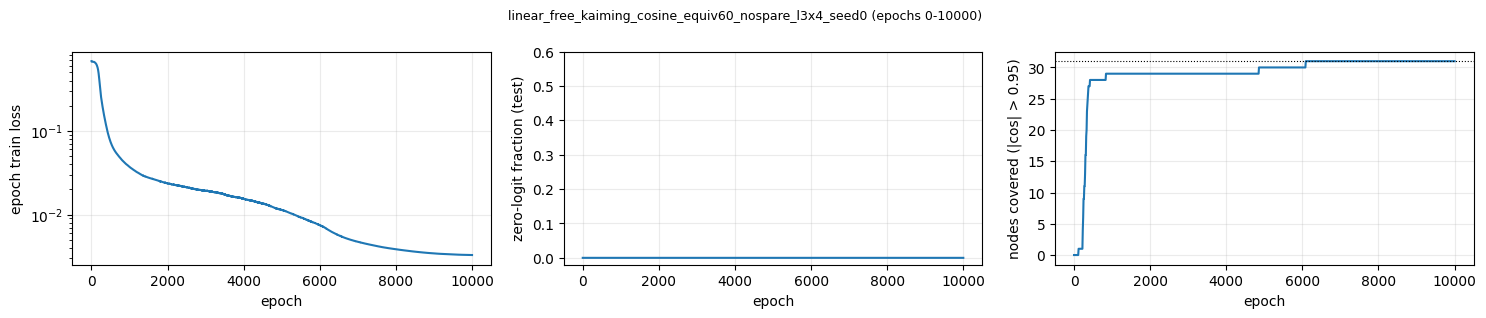

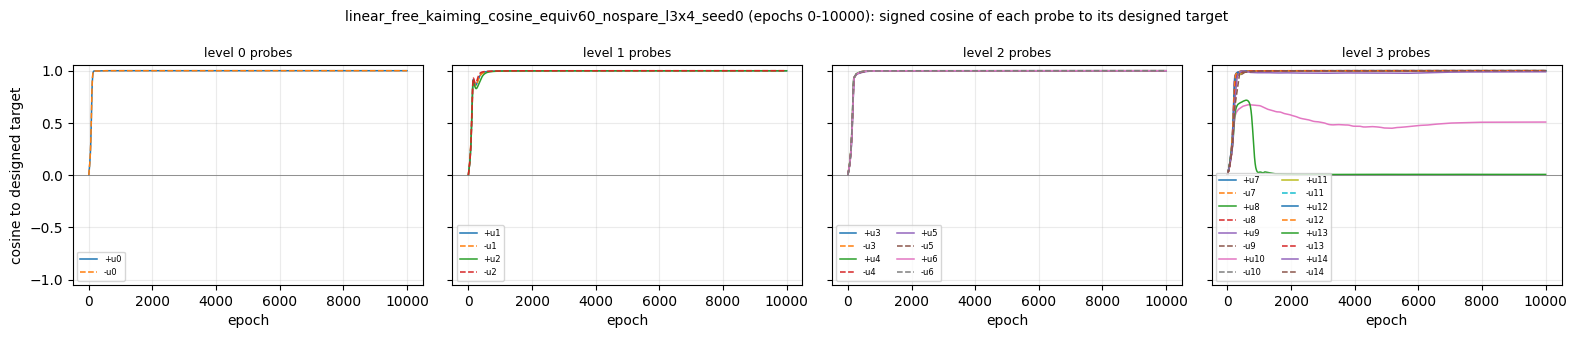

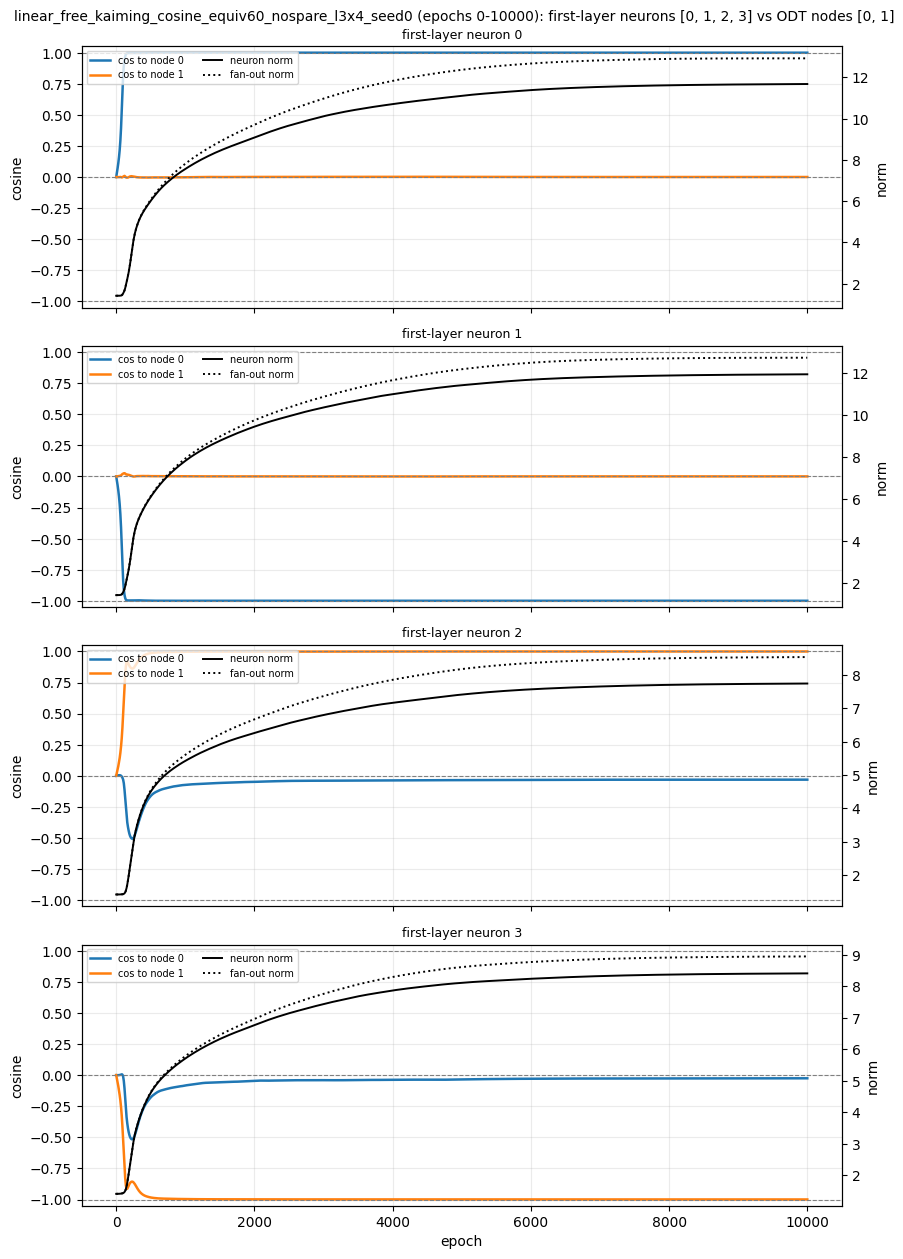

In [3]:
NEURON_IDS = [0, 1, 2, 3]
series41 = trajectory_plots(run41, NEURON_IDS, node_ids=None, end_epoch=10000)

Visible edges: 696 / 3964
First-layer aligned nodes: 0 / 62


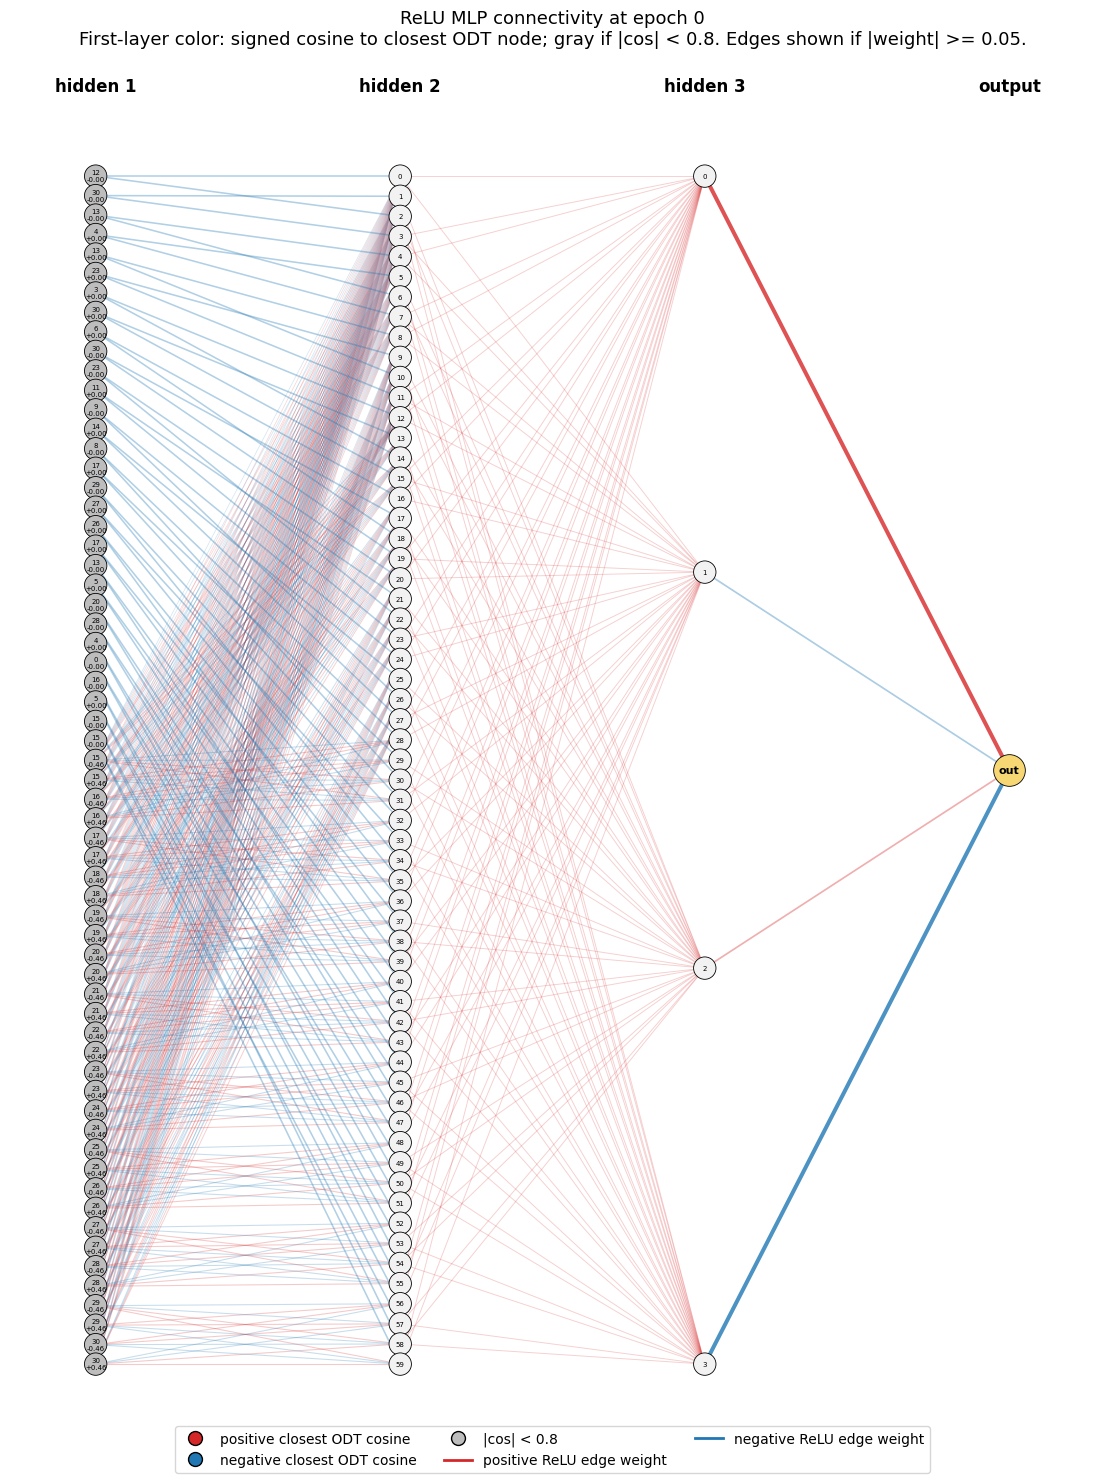

,row,group,designed_target,closest_node,level,signed_cos,norm


In [4]:
GRAPH_EPOCH = 0
table41 = network_view(run41, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.05)

## 2. Run 47: two third-layer neurons, Kaiming scale in every layer, uniform learning rate (62-60-2)

| setting | value |
|---|---|
| init | run 41's with the two redundant third-layer neurons (the 5-copy classes, which flip sign) removed: W3 = [S; Sc] with 30 entries of sqrt(2/30) = 0.258 per row, output (+1, -1); every layer's rows have norm sqrt(2) (W1 and W2 already did). The effective output weight per unit is +-0.258 (run 41: +-0.816). No gradient scales, nothing frozen |
| protocol | SGD momentum 0.9, lr 0.01 -> 0.0005 cosine, 1M points, batch 10k, 10 000 epochs |
| storage | `results/designed_init/hd2_run2_l3x2_kaiming/replay/` |
| script | `run_hd2_l3x2.py --out hd2_run2_l3x2_kaiming --tag hd2_run2_l3x2_kaiming_seed0` (the folder keeps its pre-renumbering name) |

**Findings.**
- Loss 0.0102, test error 0.71%, 29 of 31 nodes, no spikes, 28 min; run 41: 0.0033 / 0.49% / 31. Slower throughout: loss 0.1 at epoch 1039 (run 41: 418), 0.05 at 2611 (716), never below 0.01 (5326).
- Fates: 19 of 30 probes on their own node (run 41: 28); 8 deviations, all level-3 probes going to a child level-4 node (-u_7 -> u_16, +u_8 -> -u_17, ..., +u_14 -> -u_29), 0 unrelated, and three level-3 probes short of capture; the cues end 10 on their own normal and 13 on ancestors (run 41: 23 / 7). The lineage rule holds; the level-3 / level-4 competition is lost more often.
- Two third-layer neurons are enough: the output ends at (+21.3, -21.2) and W3 entries reach 5.5, a readout as large as run 41's (|w_eff| 76 vs 110). What the run lacks is the *initial* readout scale: the Kaiming rows give an effective output weight of +-0.258 per unit against run 41's +-0.816, and since the factorised readout grows at a rate set by its own size, the early phase is six times slower (|w_eff| 5.4 vs 33 at epoch 100, 49 vs 86 at epoch 1000). The first layer catches up only partly (level-3 own-coordinate spread 0.07 / 1.55 / 4.1 at epochs 200 / 1000 / 10000 vs 0.49 / 3.4 / 5.2).
- So the reduction to two neurons costs nothing in principle, and the gap to run 41 is a readout-scale effect: a run 3 with the same two-neuron Kaiming design but the readout scaled to +-0.816 (output +-sqrt(10), or W3 rows at norm 2 sqrt 2) would separate the two (run 48).


In [5]:
sr47, run47 = load_replay_run("hd2_run2_l3x2_kaiming", [62, 60, 2])          # ~20 s
summary47 = findings_table(run47)

,hd2_run2_l3x2_kaiming_seed0
final epoch loss,0.0102
test error (logit >= 0),0.0072
test error (strict),0.0072
zero-logit fraction,0.0
negative output weights,1
epochs to 0.3 / 0.1 / 0.05,367 / 1039 / 2611
aligned rows,50 / 62
nodes covered,"29 / 31, missing [25, 26]"
own-probe nodes / intended / opposite,12 / 12 / 0
missed by own probes,"[8, 12, 14]"


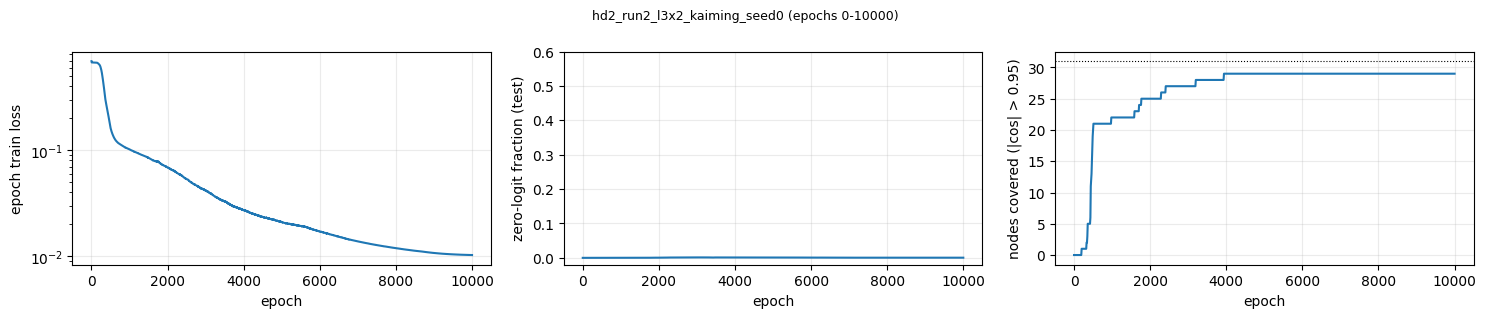

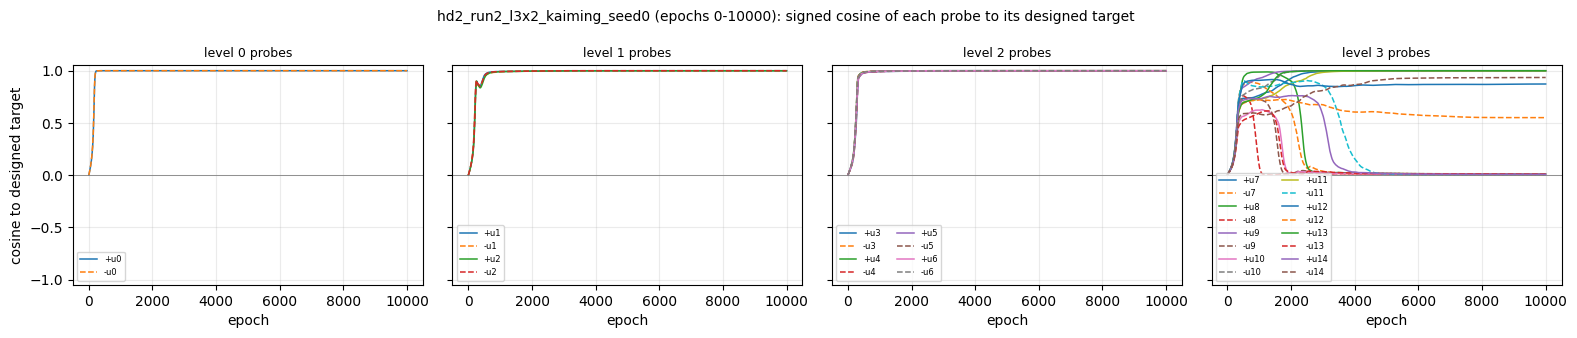

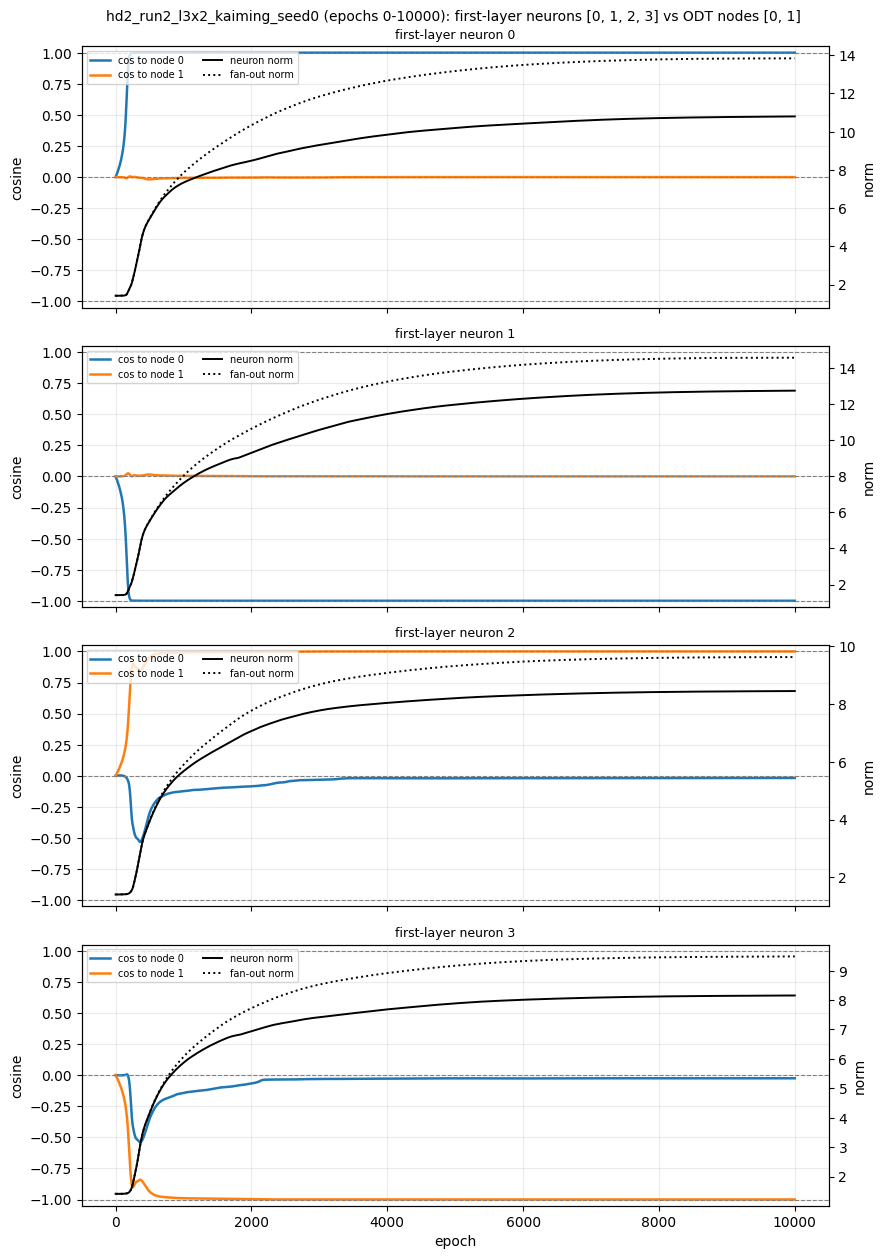

In [6]:
NEURON_IDS = [0, 1, 2, 3]
series47 = trajectory_plots(run47, NEURON_IDS, node_ids=None, end_epoch=10000)

Visible edges: 1053 / 3842
First-layer aligned nodes: 53 / 62


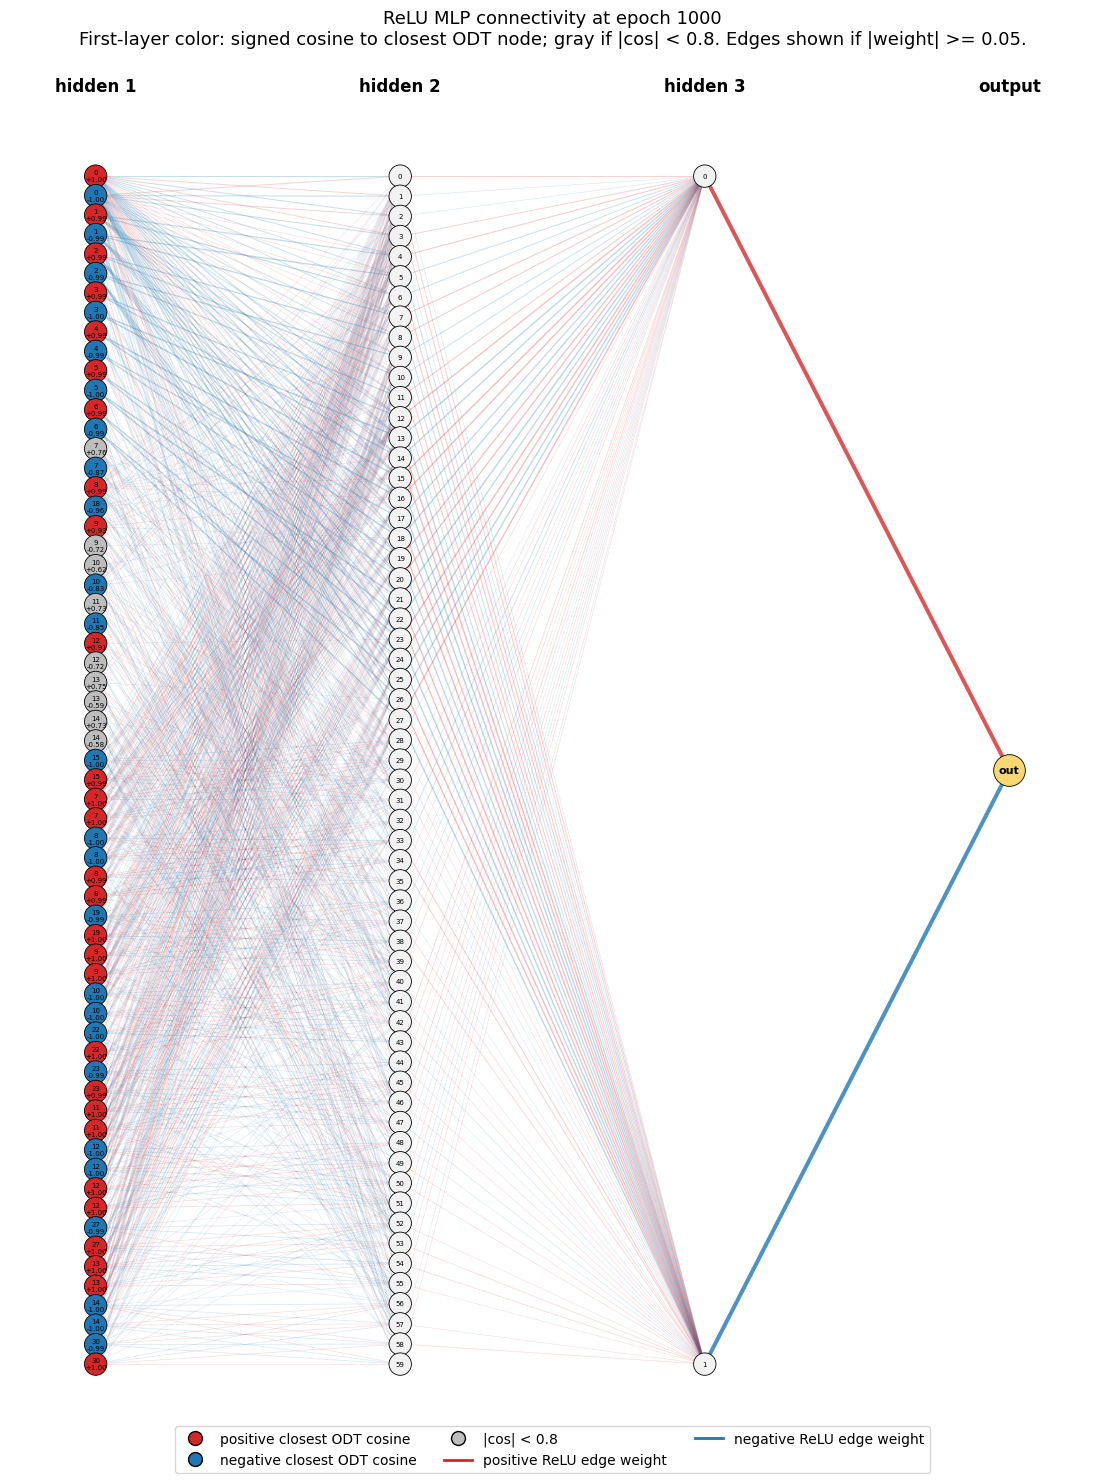

,row,group,designed_target,closest_node,level,signed_cos,norm
0,1,probe,"(0, -1)",0,0,-1.000,7.63
1,0,probe,"(0, 1)",0,0,1.000,7.33
2,3,probe,"(1, -1)",1,1,-0.990,5.87
3,2,probe,"(1, 1)",1,1,0.992,5.67
4,5,probe,"(2, -1)",2,1,-0.992,5.70
5,4,probe,"(2, 1)",2,1,0.991,5.85
6,7,probe,"(3, -1)",3,2,-0.996,4.94
7,6,probe,"(3, 1)",3,2,0.993,3.99
8,9,probe,"(4, -1)",4,2,-0.991,4.01
9,8,probe,"(4, 1)",4,2,0.995,4.92


In [8]:
GRAPH_EPOCH = 1000
table47 = network_view(run47, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.05)

In [ ]:
# Cross-run cell: uses runs 41 and 47 (loads run 41 if needed). Loss, fates, the two output weights and the effective output scale against run 1.
ensure_runs(41)
from layer_lenses.designed_init import probe_deviation_lineage
_rows = []
for n in [41, 47]:
    r = globals()[f"run{n}"]; W = r["W"]; lin = probe_deviation_lineage(W["hidden_layers.0.weight"][-1], tree); s = r["summary"]; L = r["losses"]; d = np.abs(np.diff(np.log(L)))
    w_eff = W["output_layer.weight"][:, 0, :] @ W["hidden_layers.2.weight"]
    _rows.append({"run": n, "dims": r["dims"], "final loss": round(float(s.final_epoch_loss), 4), "test error": round(float(s.test_error_end), 4), "nodes": int(s.nodes_covered_end), "probes own node": int((~lin.deviated & (lin.end_cos.abs() >= 0.95)).sum()),
                  "spiky epochs": int((d > 0.3).sum()), "epoch to 0.1 / 0.05 / 0.01": f"{int(s['epoch_to_0.1'])} / {int(s['epoch_to_0.05'])} / {int(np.argmax(L <= 0.01)) + 1 if (L <= 0.01).any() else -1}",
                  "w_out end": np.round(W["output_layer.weight"][-1][0], 2).tolist(), "|w_eff| ep 100 / 1000 / end": " / ".join(f"{np.abs(w_eff[int(np.searchsorted(r['epochs'], e))]).mean():.1f}" for e in (100, 1000, int(r["epochs"][-1])))})
print(pd.DataFrame(_rows).to_string(index=False))
plt.figure(figsize=(8, 3)); [plt.plot(globals()[f"run{n}"]["losses"], lw=0.7, label=f"run {n}") for n in [41, 47]]; plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("epoch loss"); plt.legend(); plt.show()

## 3. Run 48: run 47 with the readout rescaled to run 41's

| setting | value |
|---|---|
| init | run 47's (62-60-2, uniform lr) with the readout rescaled: W3 entries e = 1.633 (rows S, Sc at norm 8.9), output w = +-0.5, so the effective output weight per unit is e w = +-0.816 as in run 41 **and** the factorised readout's shared-mode rate at init, lr x (30 e^2 + 2 w^2) = 80.5 lr, matches run 41's full model (30 x 2.67 + 2 = 82); run 47 had 4, and either single-layer rescaling to +-0.816 (e = 0.816, w = 1 or e = 0.258, w = 3.16) would give 22. Logit rms at init 0.049 (run 41: 0.049, run 47: 0.016) |
| protocol | run 47's: SGD momentum 0.9, lr 0.01 -> 0.0005 cosine, 1M points, batch 10k, 10 000 epochs |
| storage | `results/designed_init/hd2_run48_l3x2_readout/replay/` |
| script | `run_hd2_l3x2.py --w3-entry 1.633 --out-weight 0.5` |

**Findings.** (to be filled when the run finishes)


In [ ]:
sr48, run48 = load_replay_run("hd2_run48_l3x2_readout", [62, 60, 2])          # ~20 s
summary48 = findings_table(run48)

In [ ]:
NEURON_IDS = [0, 1, 2, 3]
series48 = trajectory_plots(run48, NEURON_IDS, node_ids=None, end_epoch=int(run48["epochs"][-1]))

In [ ]:
GRAPH_EPOCH = 0
table48 = network_view(run48, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.05)

## 4. Run 49: run 48 with ten times the data (10M points, same 1M steps)

| setting | value |
|---|---|
| init | run 48's |
| protocol | 10M training points (seed 5178, chunked), batch 10k, 1000 epochs of 1000 steps: the same 1M steps and the same cosine schedule in step units as run 48; each point is seen 100 times instead of 1000; snapshots every epoch (1000 steps, as before) |
| storage | `results/designed_init/hd2_run49_l3x2_readout_10M/replay/` |
| script | `run_hd2_l3x2.py --w3-entry 1.633 --out-weight 0.5 --n-train 10000000 --epochs 1000 --snap 1` |

**Findings.** (to be filled when the run finishes)


In [ ]:
sr49, run49 = load_replay_run("hd2_run49_l3x2_readout_10M", [62, 60, 2])          # ~20 s
summary49 = findings_table(run49)

In [ ]:
NEURON_IDS = [0, 1, 2, 3]
series49 = trajectory_plots(run49, NEURON_IDS, node_ids=None, end_epoch=int(run49["epochs"][-1]))

In [ ]:
GRAPH_EPOCH = 0
table49 = network_view(run49, GRAPH_EPOCH, align_threshold=0.8, edge_threshold=0.05)

In [ ]:
# Cross-run cell: uses runs 41, 47, 48 and 49 (loads the missing ones). Readout scale and data size: loss, fates, output growth, congruence. x axis in steps for run 49.
ensure_runs(41, 47, 48)
from layer_lenses.designed_init import probe_deviation_lineage, cue_row_identity, node_ancestors, symmetric_coordinates, symmetric_class_summary
_rows = []
for n in [41, 47, 48, 49]:
    r = globals()[f"run{n}"]; W = r["W"]; sr = globals()[f"sr{n}"]; steps_per_epoch = int(sr["data_spec"]["n_train"]) // 10_000; lin = probe_deviation_lineage(W["hidden_layers.0.weight"][-1], tree); s = r["summary"]; L = r["losses"]; d = np.abs(np.diff(np.log(L)))
    w_eff = W["output_layer.weight"][:, 0, :] @ W["hidden_layers.2.weight"]; cr = sr["design"]["cue_rows"]; cid = cue_row_identity(W["hidden_layers.0.weight"][0].astype(np.float64), tree, cr); inv = {v: k for k, v in cid.items()}
    C = W["hidden_layers.0.weight"][-1] / np.linalg.norm(W["hidden_layers.0.weight"][-1], axis=1, keepdims=True) @ tree.w_list.T
    summ = symmetric_class_summary(symmetric_coordinates(W["hidden_layers.0.weight"][-1].astype(np.float64), tree, cue_rows=cr, cue_identity=cid)).set_index("cls")
    _rows.append({"run": n, "points": sr["data_spec"]["n_train"], "final loss": round(float(s.final_epoch_loss), 4), "test error": round(float(s.test_error_end), 4), "nodes": int(s.nodes_covered_end), "probes own": int((~lin.deviated & (lin.end_cos.abs() >= 0.95)).sum()), "unrelated": int((lin.relation == "unrelated").sum()),
                  "cues own / anc": f"{sum(1 for rr in cr if abs(C[rr]).argmax() == inv[rr][0] and abs(C[rr]).max() > 0.95)} / {sum(1 for rr in cr if abs(C[rr]).max() > 0.95 and abs(C[rr]).argmax() in node_ancestors(inv[rr][0]))}", "spiky": int((d > 0.3).sum()),
                  "step to loss 0.1 / 0.05": f"{int(s['epoch_to_0.1']) * steps_per_epoch} / {int(s['epoch_to_0.05']) * steps_per_epoch}", "|w_eff| at 10k / 100k steps / end": " / ".join(f"{np.abs(w_eff[int(np.searchsorted(r['epochs'] * steps_per_epoch, st))]).mean():.1f}" for st in (10_000, 100_000, 1_000_000)),
                  "L3 own spread end": round(float(summ.loc["probe_L3", "own_spread"]), 2)})
print(pd.DataFrame(_rows).to_string(index=False))
plt.figure(figsize=(9, 3.5))
for n in [41, 47, 48, 49]:
    r = globals()[f"run{n}"]; spe = int(globals()[f"sr{n}"]["data_spec"]["n_train"]) // 10_000; plt.plot(np.arange(1, len(r["losses"]) + 1) * spe, r["losses"], lw=0.7, label=f"run {n}")
plt.xscale("log"); plt.yscale("log"); plt.xlabel("step"); plt.ylabel("epoch-mean loss"); plt.legend(); plt.show()